# 🪸 Coral Bleaching — Boosting (XGBoost, LightGBM), SVM, Neural Network
**2107541 ML for Environmental Applications · Project 2**

Notebook นี้: โหลดข้อมูล clean จาก GitHub → แบ่ง train/test → **จูน hyperparameter** 4 โมเดล → เปรียบเทียบผล → **interpretation** (permutation importance, partial dependence, ablation, global vs SEA)

⏱️ รันทั้งหมดประมาณ 20–25 นาที (Runtime → Run all)

In [1]:
!pip install -q xgboost lightgbm

## 0. ตั้งค่า
| ตัวเลือก | ค่าเริ่มต้น | ความหมาย |
|---|---|---|
| `TARGET` | `"bleach_class"` | 3 คลาส none / mild / severe — ถ้าจะเทียบกับ notebook RF ของเพื่อน (ใช้ `bleached` 0/1) ให้เปลี่ยนเป็น `"bleached"` |
| `EXCLUDE_DONNER` | `True` | ตัดแหล่งที่ไม่มีข้อมูล "ไม่ฟอกขาว" (presence-only) ออก |
| `GROUP_SPLIT` | `True` | แบ่ง train/test ตาม site (กัน leakage) — `False` = สุ่มธรรมดาแบบ `train_test_split` |

In [2]:
TARGET = "bleach_class"      # "bleach_class" (3 classes) หรือ "bleached" (0/1)
EXCLUDE_DONNER = True
GROUP_SPLIT = True
SEED = 42
N_ITER = {"XGBoost": 20, "LightGBM": 20, "SVM": 12, "NeuralNet": 15}   # ลดลงถ้าอยากรันเร็ว
SVM_MAX_TUNE = 5000

BASE = "https://raw.githubusercontent.com/Athenessa/water-quality-machine-learning/main/data/"

In [3]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, ConfusionMatrixDisplay)
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, KFold, RandomizedSearchCV,
                                     train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

## 1. โหลดข้อมูล
- ใช้ไฟล์ที่ clean แล้วจาก `data/` ใน repo
- **ตัด Donner, Nuryana, Setiawan:** แหล่งเหล่านี้มีแถว "ไม่ฟอกขาว" 0% (บันทึกเฉพาะเหตุการณ์ที่ฟอกขาว) ถ้าเก็บไว้ โมเดลจะเรียนรู้ bias จากวิธีเก็บข้อมูล

In [4]:
df = pd.read_csv(BASE + "coral_clean_global.csv")
dd = pd.read_csv(BASE + "data_dictionary.csv")
print("Raw:", df.shape)

display(df.groupby("data_source")["percent_bleaching"]
          .agg(rows="count", pct_zero=lambda s: round((s == 0).mean() * 100, 1)))

if EXCLUDE_DONNER:
    df = df[~df["data_source"].isin(["Donner", "Nuryana", "Setiawan"])].reset_index(drop=True)
print("Used:", df.shape)

FEATURES = dd.loc[dd["role"] == "feature", "attribute"].tolist()
CAT = ["exposure", "ocean_name", "realm_name"]
NUM = [c for c in FEATURES if c not in CAT]

if TARGET == "bleach_class":
    CLASSES = ["none", "mild", "severe"]
    y = df[TARGET].map({c: i for i, c in enumerate(CLASSES)}).astype(int)
else:
    CLASSES = ["not bleached", "bleached"]
    y = df[TARGET].astype(int)
X, groups = df[FEATURES], df["site_id"]
print("Features:", len(FEATURES))
display(pd.Series(y).map(dict(enumerate(CLASSES))).value_counts(normalize=True).mul(100).round(1).rename("% of rows"))

Raw: (23271, 31)


,rows,pct_zero
data_source,,
AGRRA,2847,41.8
Donner,5769,0.0
FRRP,2394,8.4
Kumagai,660,49.8
McClanahan,218,0.9
Nuryana,5,0.0
Reef_Check,11297,66.1
Safaie,77,27.3
Setiawan,4,0.0


Used: (17493, 31)
Features: 21


,% of rows
bleach_class,
none,52.6
mild,41.4
severe,6.0


## 2. แบ่ง train / test
**แบ่งตาม site:** site เดียวกันถูกสำรวจหลายครั้ง ถ้าสุ่มแบ่ง site เดียวกันจะอยู่ทั้งใน train และ test โมเดลจะจำ site ได้ ผลจึงดูดีเกินจริง แบบนี้ test คือแนวปะการังที่โมเดลไม่เคยเห็น

In [5]:
if GROUP_SPLIT:
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
    CV = GroupKFold(n_splits=5)
else:
    tr, te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=SEED, stratify=y)
    CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
X_tr, X_te, y_tr, y_te, g_tr = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te], groups.iloc[tr]
print(f"Train {len(tr)} rows / {g_tr.nunique()} sites | Test {len(te)} rows / {groups.iloc[te].nunique()} sites")
print("Sites in both:", len(set(g_tr) & set(groups.iloc[te])))

Train 13944 rows / 6163 sites | Test 3549 rows / 1541 sites
Sites in both: 0


## 3. Preprocessing (ใน Pipeline)
Impute median / most frequent → StandardScaler → One-hot ทุกขั้นอยู่**ใน Pipeline** จึงถูก fit บน training fold เท่านั้น ข้อมูลจาก test ไม่รั่วเข้า train และ SVM กับ NN ต้องใช้ข้อมูลที่ scale แล้ว

In [6]:
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])

## 4. Hyperparameter tuning
- `RandomizedSearchCV` + 5-fold CV (ตาม site) วัดผลด้วย **macro-F1** เพราะคลาส severe มีน้อย ถ้าใช้ accuracy โมเดลที่ไม่เคยทาย severe เลยก็ยังได้คะแนนสูง
- **Random search** ครอบคลุมช่วงค่าหลายมิติได้ดีกว่า grid search ในจำนวนรอบที่เท่ากัน
- **Class imbalance:** LightGBM, SVM ใช้ `class_weight="balanced"` ส่วน XGBoost ใช้ `sample_weight` (MLP ของ sklearn ไม่รองรับ)
- **SVM** จูนบน subsample 5,000 แถว เพราะเวลาเทรนเพิ่มประมาณ n² แล้วค่อย refit บน train ทั้งหมด

In [7]:
MODELS = {
    "XGBoost": (XGBClassifier(tree_method="hist", random_state=SEED, n_jobs=-1),
                {"n_estimators": randint(150, 700), "max_depth": randint(3, 9),
                 "learning_rate": loguniform(0.01, 0.3), "subsample": uniform(0.6, 0.4),
                 "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 11),
                 "reg_lambda": loguniform(0.1, 10)}),
    "LightGBM": (LGBMClassifier(class_weight="balanced", subsample_freq=1, random_state=SEED,
                                n_jobs=-1, verbose=-1),
                 {"n_estimators": randint(150, 700), "num_leaves": randint(15, 128),
                  "learning_rate": loguniform(0.01, 0.3), "min_child_samples": randint(10, 100),
                  "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
                  "reg_lambda": loguniform(0.1, 10)}),
    "SVM": (SVC(kernel="rbf", class_weight="balanced", random_state=SEED),
            {"C": loguniform(0.1, 100), "gamma": loguniform(1e-3, 1)}),
    "NeuralNet": (MLPClassifier(early_stopping=True, max_iter=400, random_state=SEED),
                  {"hidden_layer_sizes": [(64,), (128,), (64, 32), (128, 64), (128, 64, 32)],
                   "alpha": loguniform(1e-5, 1e-1), "learning_rate_init": loguniform(1e-4, 1e-2),
                   "batch_size": [64, 128, 256]}),
}

def scores(name, p, cv_mean=np.nan, cv_std=np.nan, mins=0):
    f1s = f1_score(y_te, p, average=None, labels=range(len(CLASSES)))
    return {"model": name, "cv_macro_f1": cv_mean, "cv_std": cv_std,
            "test_macro_f1": f1_score(y_te, p, average="macro"),
            "test_balanced_acc": balanced_accuracy_score(y_te, p), "test_accuracy": accuracy_score(y_te, p),
            **{f"f1_{c}": s for c, s in zip(CLASSES, f1s)}, "tune_min": mins}

results, best_params, fitted = [], {}, {}
base = Pipeline([("prep", clone(prep)), ("m", DummyClassifier(strategy="most_frequent"))]).fit(X_tr, y_tr)
results.append(scores("Baseline (majority class)", base.predict(X_te)))

In [8]:
for name, (est, space) in MODELS.items():
    t0 = time.time()
    pipe = Pipeline([("prep", clone(prep)), ("model", clone(est))])
    search = RandomizedSearchCV(pipe, {f"model__{k}": v for k, v in space.items()}, n_iter=N_ITER[name],
                                scoring="f1_macro", cv=CV, random_state=SEED, n_jobs=1, refit=False)
    Xs, ys, gs = X_tr, y_tr, g_tr
    if name == "SVM" and len(X_tr) > SVM_MAX_TUNE:
        idx = X_tr.sample(SVM_MAX_TUNE, random_state=SEED).index
        Xs, ys, gs = X_tr.loc[idx], y_tr.loc[idx], g_tr.loc[idx]
    kw = {"model__sample_weight": compute_sample_weight("balanced", ys)} if name == "XGBoost" else {}
    search.fit(Xs, ys, groups=gs if GROUP_SPLIT else None, **kw)

    i = search.best_index_
    final = Pipeline([("prep", clone(prep)), ("model", clone(est))]).set_params(**search.best_params_)
    kw = {"model__sample_weight": compute_sample_weight("balanced", y_tr)} if name == "XGBoost" else {}
    final.fit(X_tr, y_tr, **kw)
    fitted[name] = final
    best_params[name] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    results.append(scores(name, final.predict(X_te), search.cv_results_["mean_test_score"][i],
                          search.cv_results_["std_test_score"][i], (time.time() - t0) / 60))
    print(f"{name:10s} CV {results[-1]['cv_macro_f1']:.3f} ± {results[-1]['cv_std']:.3f} | "
          f"test {results[-1]['test_macro_f1']:.3f} | {results[-1]['tune_min']:.1f} min")

XGBoost    CV 0.711 ± 0.011 | test 0.746 | 6.0 min
LightGBM   CV 0.714 ± 0.014 | test 0.744 | 8.3 min
SVM        CV 0.625 ± 0.019 | test 0.701 | 1.1 min
NeuralNet  CV 0.652 ± 0.024 | test 0.670 | 4.4 min


In [9]:
# best hyperparameters
for name, bp in best_params.items():
    print(f"{name}: " + ", ".join(f"{k}={round(v, 4) if isinstance(v, float) else v}" for k, v in bp.items()))

XGBoost: colsample_bytree=0.8022, learning_rate=0.0627, max_depth=7, min_child_weight=4, n_estimators=674, reg_lambda=0.1425, subsample=0.7159
LightGBM: colsample_bytree=0.716, learning_rate=0.0269, min_child_samples=68, n_estimators=660, num_leaves=56, reg_lambda=0.124, subsample=0.9895
SVM: C=6.3584, gamma=0.1331
NeuralNet: alpha=0.0007, batch_size=64, hidden_layer_sizes=(128, 64), learning_rate_init=0.0002


**📝 อ่านผลการจูน**
| Model | Best params | CV macro-F1 |
|---|---|---|
| XGBoost | n_estimators 674, max_depth 7, learning_rate 0.063, subsample 0.72, colsample_bytree 0.80, min_child_weight 4, reg_lambda 0.14 | 0.711 ± 0.011 |
| LightGBM | n_estimators 660, num_leaves 56, learning_rate 0.027, min_child_samples 68, subsample 0.99, colsample_bytree 0.72, reg_lambda 0.12 | 0.714 ± 0.014 |
| SVM | C 6.36, gamma 0.133 | 0.625 ± 0.019 |
| Neural Net | hidden (128, 64), alpha 0.0007, learning_rate_init 0.0002, batch 64 | 0.652 ± 0.024 |

- **Boosting ทั้งสองตัวเลือกต้นไม้จำนวนมาก (660–674 ต้น) คู่กับ learning rate ต่ำ** คือค่อยๆ เรียนทีละน้อยแต่เรียนหลายรอบ ซึ่งมักทำให้ generalize ได้ดีกว่าการเรียนเร็วๆ ไม่กี่รอบ
- **XGBoost เลือกต้นไม้ค่อนข้างลึก (7)** แปลว่าในข้อมูลมี interaction หลายชั้น เช่น ความร้อน × ความลึก × ภูมิภาค และมีการกัน overfit ด้วยการสุ่มใช้ข้อมูล 72% ต่อต้น (subsample) กับ `min_child_weight` = 4
- **LightGBM ใช้ `min_child_samples` = 68** บังคับให้แต่ละใบต้องมีข้อมูลอย่างน้อย 68 แถว กันไม่ให้โมเดลจำข้อมูลรายจุด
- **SVM ได้ C และ gamma ระดับกลาง** ไม่ได้อยู่ที่ขอบของช่วงที่ค้น แปลว่าช่วงที่ตั้งไว้กว้างพอ
- **NN เลือก 2 ชั้นกับ learning rate ต่ำมาก (0.0002)** ต้องเรียนช้าๆ ถึงจะเสถียร
- **CV std ต่ำทุกโมเดล (±0.01–0.02)** ผลจึงคงที่ ไม่ได้ขึ้นกับว่า site ไหนตกอยู่ใน fold ไหน

## 5. ผลลัพธ์บน test

,model,cv_macro_f1,cv_std,test_macro_f1,test_balanced_acc,test_accuracy,f1_none,f1_mild,f1_severe,tune_min
0,Baseline (majority class),NaN,NaN,0.230,0.333,0.526,0.690,0.000,0.000,0.000
1,XGBoost,0.711,0.011,0.746,0.751,0.769,0.812,0.720,0.705,5.979
2,LightGBM,0.714,0.014,0.744,0.746,0.769,0.812,0.722,0.697,8.281
3,SVM,0.625,0.019,0.701,0.719,0.743,0.793,0.696,0.614,1.083
4,NeuralNet,0.652,0.024,0.670,0.643,0.724,0.779,0.668,0.562,4.427


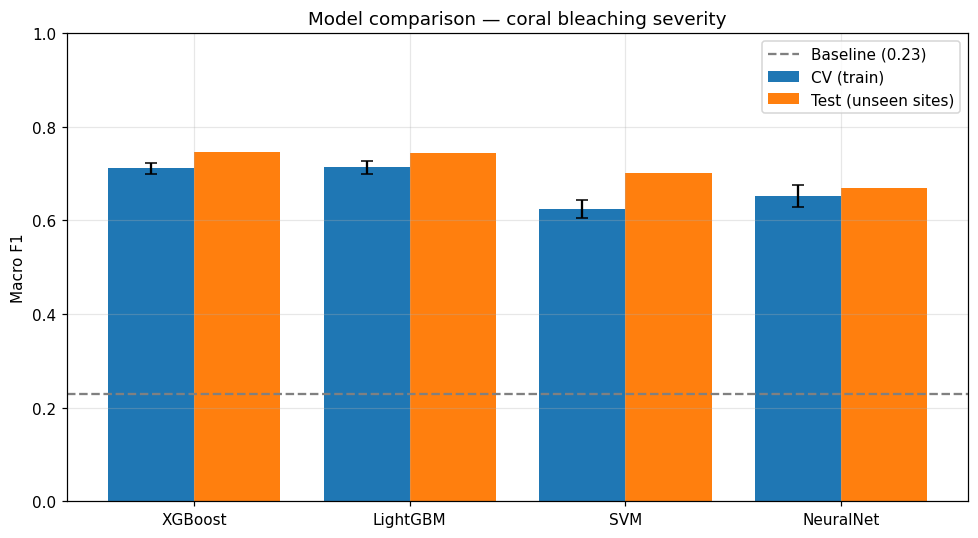

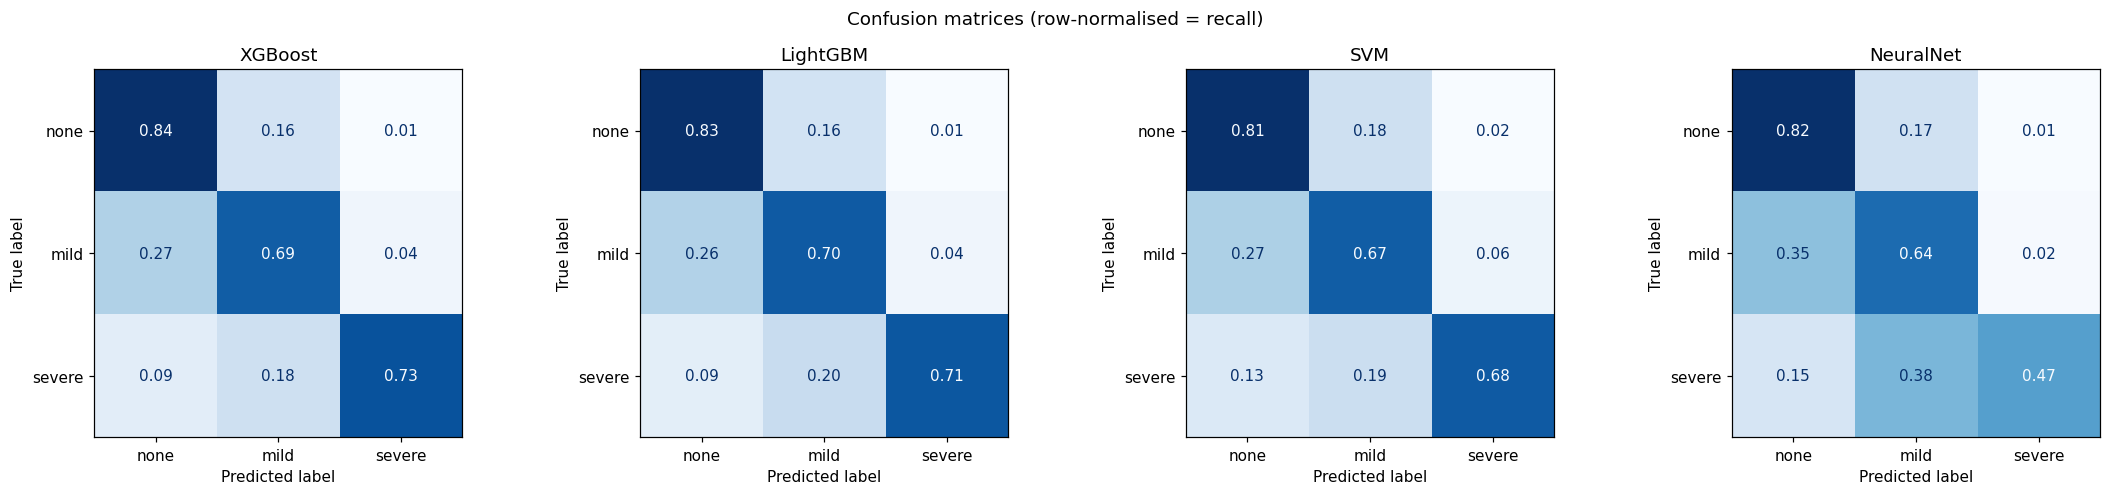

Best model: XGBoost
              precision    recall  f1-score   support

        none       0.79      0.84      0.81      1868
        mild       0.75      0.69      0.72      1468
      severe       0.68      0.73      0.70       213

    accuracy                           0.77      3549
   macro avg       0.74      0.75      0.75      3549
weighted avg       0.77      0.77      0.77      3549



In [10]:
res = pd.DataFrame(results).round(3)
display(res)

r = res[~res["model"].str.startswith("Baseline")]
x = np.arange(len(r))
base_f1 = res.loc[res["model"].str.startswith("Baseline"), "test_macro_f1"].item()
plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, r["cv_macro_f1"], 0.4, yerr=r["cv_std"], capsize=4, label="CV (train)")
plt.bar(x + 0.2, r["test_macro_f1"], 0.4, label="Test (unseen sites)")
plt.axhline(base_f1, color="gray", ls="--", label=f"Baseline ({base_f1:.2f})")
plt.xticks(x, r["model"]); plt.ylabel("Macro F1"); plt.ylim(0, 1)
plt.title("Model comparison — coral bleaching severity")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(fitted), figsize=(5 * len(fitted), 4.5))
for ax, (name, m) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, m.predict(X_te), normalize="true"),
                           display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion matrices (row-normalised = recall)"); plt.tight_layout(); plt.show()

BEST = r.sort_values("test_macro_f1", ascending=False).iloc[0]["model"]
bm = fitted[BEST]
print("Best model:", BEST)
print(classification_report(y_te, bm.predict(X_te), target_names=CLASSES))

**📝 อ่านผลบน test (แนวปะการังที่โมเดลไม่เคยเห็น)**
| Model | Macro-F1 | F1 none | F1 mild | F1 severe |
|---|---|---|---|---|
| **XGBoost** ⭐ | **0.746** | 0.812 | 0.720 | **0.705** |
| LightGBM | 0.744 | 0.812 | 0.722 | 0.697 |
| SVM | 0.701 | 0.793 | 0.696 | 0.614 |
| Neural Net | 0.670 | 0.779 | 0.668 | 0.562 |
| Baseline | 0.230 | 0.690 | 0 | 0 |

**ทำไมผลออกมาแบบนี้**
- **Boosting ชนะ (XGBoost ≈ LightGBM ต่างกันแค่ 0.002):** ข้อมูลเป็นตาราง ตัวแปรมีหลายสเกล และความสัมพันธ์ไม่เป็นเส้นตรง เช่น ผลของความร้อนเป็น threshold แล้วอิ่มตัว (ดู 6.2) ต้นไม้ตัดช่วงค่าแบบนี้ได้ดีและจับ interaction ได้เอง ส่วน XGBoost ทำ F1 severe ได้ดีกว่าเล็กน้อย และ severe คือคลาสที่สำคัญที่สุดสำหรับการเตือนภัย
- **ไม่ overfit:** คะแนน test (0.746) สูงกว่า CV (0.711) ไม่ได้ตกลง แปลว่าโมเดลใช้กับแนวปะการังใหม่ได้
- **SVM:** ค่า CV (0.625) ต่ำกว่า test (0.701) มาก เพราะ CV คิดจาก subsample 5,000 แถว ส่วน test ใช้โมเดลที่ refit บน train ทั้งหมด 14k แถว ข้อมูลที่มากขึ้นช่วย SVM ได้ชัด แต่ SVM ยังจัดการค่าที่หายไปและ interaction ได้ไม่เป็นธรรมชาติเท่าต้นไม้
- **NN แย่สุด โดยเฉพาะ severe (F1 0.562):** `MLPClassifier` ไม่รองรับ class weight จึงทายคลาส severe (6% ของข้อมูล) น้อยเกินไป และข้อมูลตารางระดับหมื่นแถวมักไม่พอให้ NN ชนะ boosting
- **XGBoost จับ severe ได้ 73%** (recall 0.73) ถ้ามีเหตุการณ์ฟอกขาวรุนแรง 100 ครั้ง โมเดลเตือนถูก 73 ครั้ง
- ทุกโมเดลชนะ baseline (0.23) มาก โมเดลจึงเรียนรู้จากข้อมูลจริง ไม่ได้ทายตามสัดส่วนคลาส

## 6. Interpretation
### 6.1 Permutation importance
สลับค่าของ feature ทีละตัวใน test แล้วดูว่า macro-F1 ตกลงเท่าไร ยิ่งตกมาก feature นั้นยิ่งสำคัญ วิธีนี้ใช้ได้กับทุกโมเดล จึงเทียบข้ามโมเดลได้

,XGBoost,LightGBM,SVM,NeuralNet
date_year,0.1019,0.1220,0.0969,0.0773
longitude_degrees,0.0348,0.0371,0.0449,0.0275
tsa_dhw,0.0263,0.0277,0.0489,0.0548
latitude_degrees,0.0256,0.0413,0.0673,0.0537
depth_m,0.0240,0.0268,0.0386,0.0264
cyclone_frequency,0.0175,0.0181,0.0491,0.0217
ssta_dhw,0.0164,0.0079,0.0417,0.0165
climsst,0.0144,0.0105,0.0381,0.0297
ocean_name,0.0132,0.0155,0.0112,0.0810
ssta_frequency,0.0115,0.0105,0.0479,0.0406


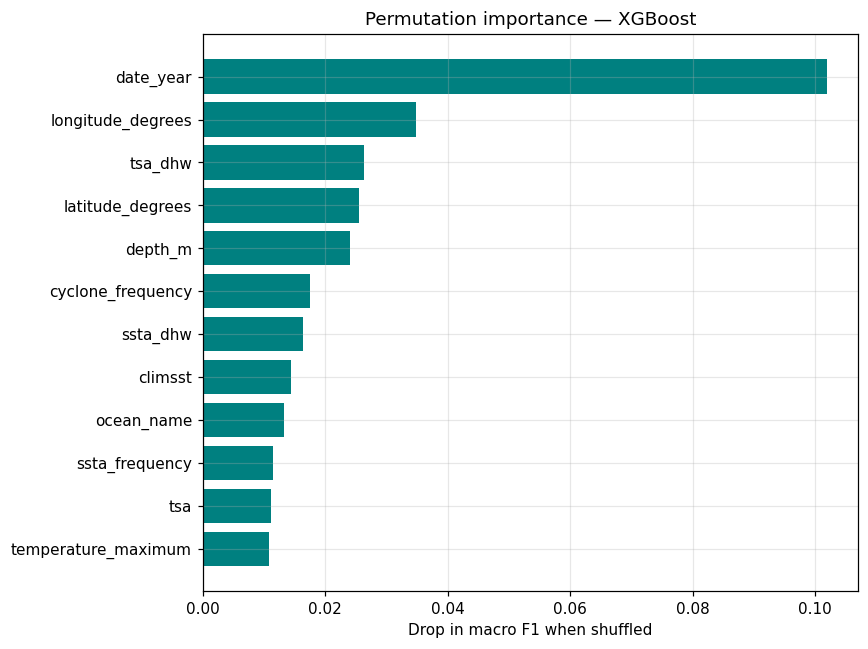

In [11]:
imp = {}
for name, m in fitted.items():
    pi = permutation_importance(m, X_te, y_te, scoring="f1_macro", n_repeats=5, random_state=SEED)
    imp[name] = pd.Series(pi.importances_mean, index=FEATURES)
imp = pd.DataFrame(imp).round(4)
imp = imp.loc[imp[BEST].sort_values(ascending=False).index]
display(imp)

top = imp[BEST].head(12)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="teal")
plt.xlabel("Drop in macro F1 when shuffled"); plt.title(f"Permutation importance — {BEST}")
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

**📝 อ่านผล permutation importance (XGBoost)**
- **`date_year` สำคัญที่สุด (0.102):** ความเสี่ยงพุ่งช่วง 2014–2016 ซึ่งตรงกับ **global bleaching event ครั้งที่ 3 (2014–2017)** ปีจึงแทนคลื่นความร้อนระดับโลกที่ค่าความร้อนรายจุดจับได้ไม่หมด แต่อาจสะท้อนโปรแกรมสำรวจที่เปลี่ยนไปตามเวลาด้วย (จึงทำ ablation ในข้อ 6.3)
- **`longitude`, `latitude` (0.035, 0.026):** แต่ละภูมิภาคเสี่ยงต่างกัน
- **`tsa_dhw` (ความร้อนสะสม) เป็นตัวแปรสิ่งแวดล้อมที่สำคัญที่สุด (0.026)** ตามด้วย **`depth_m` (0.024)** และ `cyclone_frequency` (0.018)
- **`turbidity`, `exposure`, `windspeed` มีผลน้อยมาก** (≤ 0.005)
- ทุกโมเดลให้ year, พิกัด และ DHW อยู่กลุ่มบน ผลจึงไม่ได้ขึ้นกับโมเดลใดโมเดลหนึ่ง

### 6.2 Partial dependence
เปลี่ยนค่าของ feature ทีละตัว (ตัวอื่นคงเดิม) แล้วดูว่าความน่าจะเป็นของคลาสสุดท้ายเปลี่ยนไปอย่างไร คลาสสุดท้ายคือ **severe** (หรือ bleached ถ้าใช้ target แบบ 0/1)

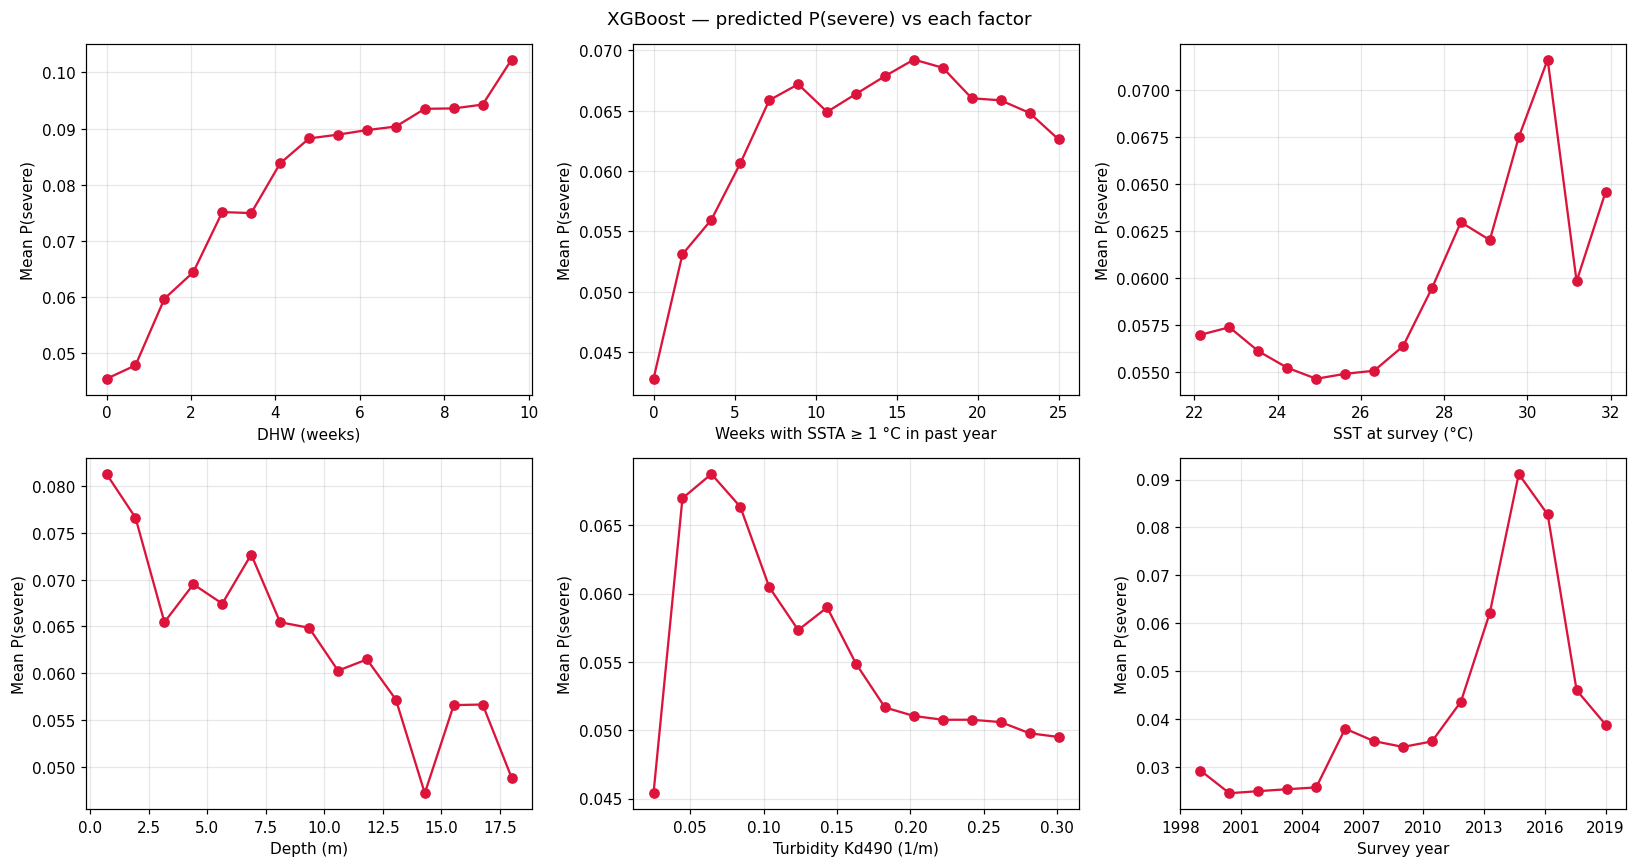

tsa_dhw             0.00 -> P=0.045 |     9.59 -> P=0.102 | max P=0.102
ssta_frequency      0.00 -> P=0.043 |    25.00 -> P=0.063 | max P=0.069
temperature_c      22.15 -> P=0.057 |    31.88 -> P=0.065 | max P=0.072
depth_m             0.70 -> P=0.081 |    18.00 -> P=0.049 | max P=0.081
turbidity           0.03 -> P=0.045 |     0.30 -> P=0.050 | max P=0.069
date_year        1999.00 -> P=0.029 |  2019.00 -> P=0.039 | max P=0.091
exposure=Exposed   -> P(severe) = 0.065
exposure=Sometimes -> P(severe) = 0.064
exposure=Sheltered -> P(severe) = 0.068


In [12]:
pd_feats = ["tsa_dhw", "ssta_frequency", "temperature_c", "depth_m", "turbidity", "date_year"]
labels = {"tsa_dhw": "DHW (weeks)", "ssta_frequency": "Weeks with SSTA ≥ 1 °C in past year",
          "temperature_c": "SST at survey (°C)", "depth_m": "Depth (m)",
          "turbidity": "Turbidity Kd490 (1/m)", "date_year": "Survey year"}
pos = CLASSES[-1]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
pdp = {}
for ax, f in zip(axes.ravel(), pd_feats):
    lo, hi = np.nanpercentile(X_te[f], [1, 99])
    grid = np.unique(np.round(np.linspace(lo, hi, 15), 4))
    Xp, vals = X_te.copy(), []
    for v in grid:
        Xp[f] = v
        vals.append(bm.predict_proba(Xp)[:, -1].mean())
    pdp[f] = (grid, vals)
    ax.plot(grid, vals, marker="o", color="crimson")
    ax.set_xlabel(labels[f]); ax.set_ylabel(f"Mean P({pos})"); ax.grid(True, alpha=0.3)
    if f == "date_year":
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.suptitle(f"{BEST} — predicted P({pos}) vs each factor"); plt.tight_layout(); plt.show()

for f, (g, v) in pdp.items():
    print(f"{f:15s} {g[0]:>8.2f} -> P={v[0]:.3f} | {g[-1]:>8.2f} -> P={v[-1]:.3f} | max P={max(v):.3f}")

Xc = X_te.copy()
for lev in ["Exposed", "Sometimes", "Sheltered"]:
    Xc["exposure"] = lev
    print(f"exposure={lev:9s} -> P({pos}) = {bm.predict_proba(Xc)[:, -1].mean():.3f}")

**📝 อ่านผล partial dependence: โอกาสฟอกขาวรุนแรง (P(severe))**
| ปัจจัย | สิ่งที่เห็น | ความหมายด้านสิ่งแวดล้อม |
|---|---|---|
| **DHW** | **4.5% → 8.8%** เมื่อ DHW 0 → ~5 สัปดาห์ แล้วอิ่มตัวที่ประมาณ 9–10% | ความเสี่ยงชันที่สุดช่วง **DHW 0–4** ใกล้เกณฑ์ของ NOAA Coral Reef Watch (4 DHW = Alert Level 1) จึงควรเริ่มเตือนตั้งแต่ DHW ประมาณ 2–4 |
| สัปดาห์ร้อนผิดปกติในรอบปี | 4.3% → ประมาณ 6.9% ที่ 15–18 สัปดาห์ | ความร้อนที่เกิดซ้ำๆ ทำให้ปะการังฟื้นตัวไม่ทัน |
| SST ตอนสำรวจ | ทรงตัวจนประมาณ 27 °C แล้วขึ้นถึงประมาณ 7% ที่ 30–31 °C | น้ำที่ร้อนเกิน 28–30 °C เพิ่มความเสี่ยง |
| **ความลึก** | น้ำตื้น 0.7 ม. **8.1%** → ลึก 18 ม. **4.9%** | ปะการังน้ำตื้นได้รับแสงและความร้อนมากกว่า **แนวที่ลึกกว่าจึงเป็นแหล่งหลบภัยที่ดีกว่า** |
| ความขุ่น | สูงสุด 6.9% ที่น้ำใสปานกลาง แล้วลดลงเหลือ 5.0% เมื่อน้ำขุ่น | สนับสนุนแนวคิดว่าน้ำขุ่นช่วยบังแสง แต่ผลมีขนาดเล็ก |
| ปี | 2–3% ในปีปกติ **พุ่งเป็น 9.1% ช่วง 2015** | global bleaching event 2014–2017 |
| Exposure | 6.4–6.8% แทบไม่ต่างกัน | ไม่พบผลของการเป็นแนวเปิดรับคลื่นหรือแนวกำบัง |

### 6.3 Ablation: ทำนายได้จากสิ่งแวดล้อมจริงไหม
"ปี" กับ "พิกัด" อาจสำคัญเพราะสะท้อนเหตุการณ์ระดับโลกหรือโปรแกรมสำรวจ ไม่ใช่สภาพแวดล้อม จึงลองเทรนโมเดลที่ดีที่สุดใหม่โดยตัดตัวแปรเหล่านี้ออก

In [ ]:
PLACE_TIME = ["latitude_degrees", "longitude_degrees", "ocean_name", "realm_name", "date_year", "date_month"]

def refit(feats, Xtr=None, ytr=None):
    Xtr = X_tr if Xtr is None else Xtr
    ytr = y_tr if ytr is None else ytr
    cat = [c for c in CAT if c in feats]; num = [c for c in feats if c not in cat]
    p = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    m = Pipeline([("prep", p), ("model", clone(MODELS[BEST][0]))]).set_params(
        **{f"model__{k}": v for k, v in best_params[BEST].items()})
    kw = {"model__sample_weight": compute_sample_weight("balanced", ytr)} if BEST == "XGBoost" else {}
    return m.fit(Xtr[feats], ytr, **kw)

abl = []
for label, feats in [("All features", FEATURES),
                     ("Without year", [f for f in FEATURES if f != "date_year"]),
                     ("Environment only", [f for f in FEATURES if f not in PLACE_TIME])]:
    p = refit(feats).predict(X_te[feats])
    abl.append({"features": label, "n": len(feats), "macro_f1": f1_score(y_te, p, average="macro"),
                f"f1_{pos}": f1_score(y_te, p, average=None)[-1]})
display(pd.DataFrame(abl).round(3))

,features,n,macro_f1,f1_severe
0,All features,21,0.746,0.705
1,Without year,20,0.719,0.659
2,Environment only,15,0.702,0.633


**📝 อ่านผล ablation**
| Features | Macro-F1 | F1 severe |
|---|---|---|
| ครบ 21 ตัว | 0.746 | 0.705 |
| ไม่มีปี | 0.719 | 0.659 |
| สิ่งแวดล้อมล้วน | 0.702 | 0.633 |

ถ้าเหลือแค่ตัวแปรความร้อนและสภาพแนวปะการัง ยังได้ macro-F1 **0.702** (baseline 0.23) แปลว่า **ทำนายจากสภาพแวดล้อมได้จริง** ไม่ได้อาศัยการจำพื้นที่หรือปี ส่วนที่หายไปประมาณ 0.04 คือข้อมูลภูมิภาคและเหตุการณ์ระดับโลกที่ค่ารายจุดอธิบายไม่ได้

### 6.4 Global vs Southeast Asia
เทียบบน test site ใน SEA ระหว่างโมเดลที่เทรนทั้งโลก กับโมเดลที่เทรนเฉพาะข้อมูล SEA

In [ ]:
sea_tr = df.iloc[tr]["is_sea"].values.astype(bool)
sea_te = df.iloc[te]["is_sea"].values.astype(bool)
print("SEA train rows:", sea_tr.sum(), "| SEA test rows:", sea_te.sum())
display(pd.Series(y_te[sea_te]).map(dict(enumerate(CLASSES))).value_counts().rename("SEA test rows"))

f1_global = f1_score(y_te[sea_te], bm.predict(X_te[sea_te]), average="macro")
sea_model = refit(FEATURES, X_tr[sea_tr], y_tr[sea_tr])
f1_sea = f1_score(y_te[sea_te], sea_model.predict(X_te[sea_te]), average="macro")
display(pd.DataFrame({"model": ["Trained on global", "Trained on SEA only"],
                      "macro_f1_on_SEA_test": [f1_global, f1_sea]}).round(3))

SEA train rows: 3639 | SEA test rows: 849


,SEA test rows
bleach_class,
none,595
mild,230
severe,24


,model,macro_f1_on_SEA_test
0,Trained on global,0.691
1,Trained on SEA only,0.666


**📝 อ่านผล global vs SEA**
- โมเดลที่เทรนทั้งโลกทำได้ **0.691** บน SEA test ดีกว่าโมเดลที่เทรนเฉพาะ SEA (**0.666**)
- **เหตุผล:** SEA มี severe น้อยมาก (24 จาก 849 แถวใน test หรือประมาณ 2.8%) ข้อมูลจากภูมิภาคอื่นจึงช่วยให้โมเดลรู้จักรูปแบบของ severe มากขึ้น
- **ข้อควรระวัง:** severe มีแค่ 24 แถว ตัวเลขนี้จึงมีความไม่แน่นอนสูง

## 7. สรุป
**ผล:** XGBoost ทำได้ดีที่สุด macro-F1 **0.746** บนแนวปะการังที่ไม่เคยเห็น และจับ severe ได้ **73%** ส่วน LightGBM ได้ผลแทบเท่ากัน (0.744) SVM 0.701 และ NN 0.670 ทุกโมเดลชนะ baseline (0.23)

**ปัจจัยสำคัญ**
1. **ความร้อนสะสม (DHW):** โอกาสฟอกขาวรุนแรงเพิ่มจาก 4.5% เป็น 8.8% เมื่อ DHW 0 → 5 สัปดาห์
2. **ความลึก:** น้ำตื้นเสี่ยงกว่าน้ำลึก (8.1% vs 4.9%)
3. **คลื่นความร้อนระดับโลก:** ปี 2014–2016 ความเสี่ยงพุ่งชัดเจน
4. ความขุ่นและการเป็นแนวกำบังคลื่นมีผลน้อย

**การนำไปใช้**
- **ฟื้นฟู:** เลือกพื้นที่ที่ลึกกว่าและมี DHW ต่ำในอดีต
- **ท่องเที่ยว:** ใช้ DHW รายสัปดาห์จาก NOAA เป็นตัวตั้งต้นเตือนภัย แล้วใช้โมเดลประเมินความเสี่ยงของแต่ละแหล่งดำน้ำ เพื่อวางแผนปิดพักแหล่งตื้นที่เสี่ยงก่อน

**ข้อจำกัด**
- ผลที่ได้คือความสัมพันธ์ ไม่ใช่เหตุและผล
- ปีและพิกัดอาจสะท้อนโปรแกรมสำรวจที่ต่างกันปนอยู่ด้วย
- ค่าความร้อนมาจากดาวเทียม ไม่ได้วัดที่ตัวปะการัง
- severe มีแค่ 6% ของข้อมูล และใน SEA test มีแค่ 24 แถว
- SVM จูนบน subsample และ NN ไม่มี class weight จึงยังปรับปรุงได้

*ตัวเลขทั้งหมดมาจากการรันครั้งนี้ (seed 42) ถ้ารันซ้ำ ตัวเลขอาจขยับเล็กน้อยตามเวอร์ชันของ library*